# 04 · Simulator

Notebook 03 told us how much volume promotions add. But more units isn't the goal. Profit is.
A deeper discount sells more, and it also gives away margin on every unit, including the units
that would have sold anyway.

This notebook uses the model from 03 to answer:

1. For each commodity, **which discount level makes the most gross profit?**
2. How does that compare with what the store does today?
3. How much does the answer depend on my assumptions (margins, and who pays for the discount)?

In [40]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

model = lgb.Booster(model_file=str(PROCESSED / "units_model.txt"))
cw = pd.read_parquet(PROCESSED / "commodity_week.parquet")

## Settings

Two assumptions drive everything here, and the dataset has neither, so both are set by hand:

- **Gross margin by department** (as % of regular shelf price). Rough, typical grocery levels.
- **Vendor-funded share of the discount.** In grocery, manufacturers often pay for part of a promotion.
  If a supplier covers half of a 20% discount, the store only gives up 10%. Starting at 0% (the store pays everything)
  is the most conservative case; the sensitivity section tries other values.

In [41]:
MARGIN_BY_DEPT = {
    "GROCERY": 0.30,
    "PRODUCE": 0.40,
    "MEAT": 0.25,
    "MEAT-PCKGD": 0.28,
    "DELI": 0.40,
    "PASTRY": 0.45,
    "SEAFOOD-PCKGD": 0.30,
    "SEAFOOD": 0.30,
    "DRUG GM": 0.35,
    "NUTRITION": 0.35,
}
DEFAULT_MARGIN = 0.30
VENDOR_FUNDED_SHARE = 0.0

# simulate over the most recent 12 weeks as a "typical period"
SIM_WEEKS = range(90, 102)
DISCOUNT_GRID = np.arange(0, 50.1, 2.5)

# "package": display/mailer move with the discount the way they usually do for that commodity
# "discount_only": display/mailer stay at the commodity's low-promo level
SIM_MODE = "package"
BANDWIDTH = 4.0   # discount points used to smooth the typical display/mailer level

# seasonal commodities: notebook 03 showed their promo effect is mixed up with seasonality
LOW_CONFIDENCE = ["SOUP", "TROPICAL FRUIT", "BERRIES", "GRAPES", "CITRUS", "APPLES",
                  "TURKEY", "SEAFOOD - FROZEN"]
MIN_AVG_DISCOUNT = 2.0     # rarely discounted: nothing to learn
MIN_UNITS_12W = 300        # too small to trust

## Rebuild the model features

Same feature code as notebook 03, so the inputs match exactly what the model was trained on.

In [42]:
df = cw.copy()
df["week_of_year"] = (df["week_no"] - 1) % 52 + 1
df["rel_list_price"] = df["avg_list_price"] / df.groupby("commodity_desc")["avg_list_price"].transform("mean")
df["commodity"] = df["commodity_desc"].astype("category")
df["dept"] = df["department"].astype("category")

DEMAND_FEATURES = ["commodity", "dept", "week_no", "week_of_year", "rel_list_price"]
PROMO_FEATURES = ["avg_discount_pct", "share_display", "share_mailer"]
FEATURES = DEMAND_FEATURES + PROMO_FEATURES

df["margin"] = df["department"].map(MARGIN_BY_DEPT).fillna(DEFAULT_MARGIN)

# a few commodity names appear in more than one department, so build a unique label for grouping
dupes = df.groupby("commodity_desc")["department"].nunique()
dupes = dupes[dupes > 1].index
df["item"] = np.where(df["commodity_desc"].isin(dupes),
                      df["commodity_desc"] + " (" + df["department"] + ")", df["commodity_desc"])
if len(dupes):
    print("names shared across departments:", list(dupes))

normal_levels = df.groupby("item")[PROMO_FEATURES].quantile(0.10)
observed = df.groupby("item")["avg_discount_pct"].agg(
    disc_p05=lambda s: s.quantile(0.05), disc_p95=lambda s: s.quantile(0.95)
)

sim = df.loc[df["week_no"].isin(SIM_WEEKS)].copy()
print(f"simulation period: weeks {min(SIM_WEEKS)}–{max(SIM_WEEKS)}, {sim['commodity_desc'].nunique()} commodities")

names shared across departments: ['APPLES', 'BACON', 'BEERS/ALES', 'BERRIES', 'BREAD', 'CANDY - CHECKLANE', 'CANDY - PACKAGED', 'DRIED FRUIT', 'EGGS', 'FD WRAPS/BAGS/TRSH BG', 'LUNCHMEAT', 'MEAT - MISC', 'MELONS', 'MILK BY-PRODUCTS', 'MISCELLANEOUS', 'NEWSPAPER', 'ORGANICS FRUIT & VEGETABLES', 'PORK', 'REFRGRATD DOUGH PRODUCTS', 'SALAD BAR', 'SEAFOOD - FROZEN', 'SEAFOOD-FRESH', 'SNACK NUTS', 'SOUP', 'TROPICAL FRUIT']
simulation period: weeks 90–101, 184 commodities


## The profit math

For one unit with regular price **P**, margin **m**, discount **d** and vendor-funded share **f**:

```
profit per unit = P × (m − (1 − f) × d)
```

With the store paying the whole discount (f = 0), a 15% discount on a 30% margin item cuts profit per unit in half.
To break even, units have to rise by `d / (m − d)`:

In [43]:
breakeven = pd.DataFrame(
    {f"margin {int(m*100)}%": [d / (m - d) * 100 if m > d else np.nan for d in [0.05, 0.10, 0.15, 0.20, 0.25]]
     for m in [0.25, 0.30, 0.40]},
    index=[f"{d}% off" for d in [5, 10, 15, 20, 25]],
)
print("Sales uplift needed just to break even, store pays the full discount (%):")
breakeven

Sales uplift needed just to break even, store pays the full discount (%):


,margin 25%,margin 30%,margin 40%
5% off,25.00,20.00,14.29
10% off,66.67,50.00,33.33
15% off,150.00,100.00,60.00
20% off,400.00,200.00,100.00
25% off,NaN,500.00,166.67


## How does the store usually run a promo?

A deep discount rarely happens on its own. It usually comes with a display and a spot in the mailer.
If the simulator only changes the discount and leaves display/mailer at their low level,
it compares "30% off with no display" against reality, which the store never does, and
the promo looks weaker than it is.

So in `package` mode, for each discount level I use the display and mailer share that commodity
typically had in weeks with a similar discount.

In [44]:
def typical_levels(g):
    x = g["avg_discount_pct"].to_numpy()
    out = []
    for d in DISCOUNT_GRID:
        w = np.exp(-0.5 * ((x - d) / BANDWIDTH) ** 2) + 1e-12
        out.append({"discount_pct": d,
                    "display": np.average(g["share_display"], weights=w),
                    "mailer": np.average(g["share_mailer"], weights=w)})
    return pd.DataFrame(out)

typical = (df.groupby("item")[["avg_discount_pct", "share_display", "share_mailer"]]
             .apply(typical_levels).reset_index(level=0).reset_index(drop=True))

if SIM_MODE == "discount_only":
    typical["display"] = typical["item"].map(normal_levels["share_display"])
    typical["mailer"] = typical["item"].map(normal_levels["share_mailer"])

typical.loc[typical["item"] == "SOFT DRINKS"].iloc[::4]

,item,discount_pct,display,mailer
3843,SOFT DRINKS,0.00,0.13,0.11
3847,SOFT DRINKS,10.00,0.16,0.17
3851,SOFT DRINKS,20.00,0.21,0.28
3855,SOFT DRINKS,30.00,0.31,0.46
3859,SOFT DRINKS,40.00,0.40,0.61
3863,SOFT DRINKS,50.00,0.44,0.67


## Simulate each discount level

Predict units for every week of the period at every discount level. Predictions are scaled per commodity
so the model's total at actual conditions matches actual units (removes model bias from the comparison).

In [45]:
def predict_units(data, discount=None, display=None, mailer=None):
    X = data[FEATURES].copy()
    if discount is not None:
        X["avg_discount_pct"] = discount
    if display is not None:
        X["share_display"] = display
    if mailer is not None:
        X["share_mailer"] = mailer
    return np.expm1(model.predict(X))

sim["pred_actual"] = predict_units(sim)
calibration = sim.groupby("item")["units"].sum() / sim.groupby("item")["pred_actual"].sum()
sim["calibration"] = sim["item"].map(calibration)

typ_idx = typical.set_index(["item", "discount_pct"])
rows = []
for d in DISCOUNT_GRID:
    key = pd.MultiIndex.from_arrays([sim["item"], np.full(len(sim), d)])
    lv = typ_idx.reindex(key)
    units = predict_units(sim, discount=d, display=lv["display"].values, mailer=lv["mailer"].values)
    rows.append(pd.DataFrame({
        "department": sim["department"].values,
        "item": sim["item"].values,
        "week_no": sim["week_no"].values,
        "discount_pct": d,
        "units": units * sim["calibration"].values,
        "list_price": sim["avg_list_price"].values,
        "margin": sim["margin"].values,
    }))
grid = pd.concat(rows, ignore_index=True)
grid["revenue"] = grid["units"] * grid["list_price"] * (1 - grid["discount_pct"] / 100)
print(f"{len(grid):,} simulated commodity-week-discount rows")

48,048 simulated commodity-week-discount rows


## Evaluate: best discount vs. today

One function does the profit calculation for any set of assumptions, so the main result and the
sensitivity checks use exactly the same logic. The best discount is only picked from inside the range
the store has actually run (5th–95th percentile of its weekly discount).

In [46]:
def direction(change_pts):
    if change_pts <= -2.5: return "discount less"
    if change_pts >= 2.5: return "discount more"
    return "about right"

def evaluate(margin_shift=0.0, vendor_share=VENDOR_FUNDED_SHARE):
    g = grid.assign(gross_profit=lambda x: x["units"] * x["list_price"]
                    * (x["margin"] + margin_shift - (1 - vendor_share) * x["discount_pct"] / 100))
    curves = (g.groupby(["department", "item", "discount_pct"], as_index=False)
                [["units", "revenue", "gross_profit"]].sum()
                .merge(observed, left_on="item", right_index=True))
    curves["in_observed_range"] = curves["discount_pct"].between(curves["disc_p05"], curves["disc_p95"])

    s = sim.assign(gross_profit=lambda x: x["units"] * x["avg_list_price"]
                   * (x["margin"] + margin_shift - (1 - vendor_share) * x["avg_discount_pct"] / 100))
    current = s.groupby(["department", "item"]).agg(
        current_discount=("avg_discount_pct", "mean"),
        current_units=("units", "sum"),
        current_revenue=("sales_value", "sum"),
        current_profit=("gross_profit", "sum"),
        margin=("margin", "first"),
    ).reset_index()

    inside = curves.loc[curves["in_observed_range"]]
    best = inside.loc[inside.groupby("item")["gross_profit"].idxmax(),
                      ["item", "discount_pct", "units", "revenue", "gross_profit"]]
    best.columns = ["item", "best_discount", "best_units", "best_revenue", "best_profit"]

    reco = current.merge(best, on="item", how="inner")
    reco["profit_change"] = reco["best_profit"] - reco["current_profit"]
    reco["units_change_%"] = (reco["best_units"] / reco["current_units"] - 1) * 100
    reco["discount_change_pts"] = reco["best_discount"] - reco["current_discount"]
    reco["recommendation"] = reco["discount_change_pts"].apply(direction)

    reco["confidence"] = "normal"
    base_name = reco["item"].str.replace(r" \([^)]*\)$", "", regex=True)
    reco.loc[base_name.isin(LOW_CONFIDENCE), "confidence"] = "low (seasonal)"
    reco.loc[reco["current_units"] < MIN_UNITS_12W, "confidence"] = "low (small volume)"
    reco.loc[reco["current_discount"] < MIN_AVG_DISCOUNT, "confidence"] = "n/a (rarely discounted)"
    return curves, reco

curves, reco = evaluate()
usable = reco.loc[reco["confidence"] == "normal"].copy()
print(reco["confidence"].value_counts(), "\n")
usable["recommendation"].value_counts()

confidence
normal                     149
n/a (rarely discounted)     26
low (small volume)          15
low (seasonal)               8
Name: count, dtype: int64 



recommendation
discount less    118
about right       31
Name: count, dtype: int64

## Profit curves

Green: gross profit over the 12 weeks. Blue dots: actual weekly units across the whole history, against
that week's discount, to check the model's units curve (dashed) against what really happened.
The shaded band is the range the store has actually run.

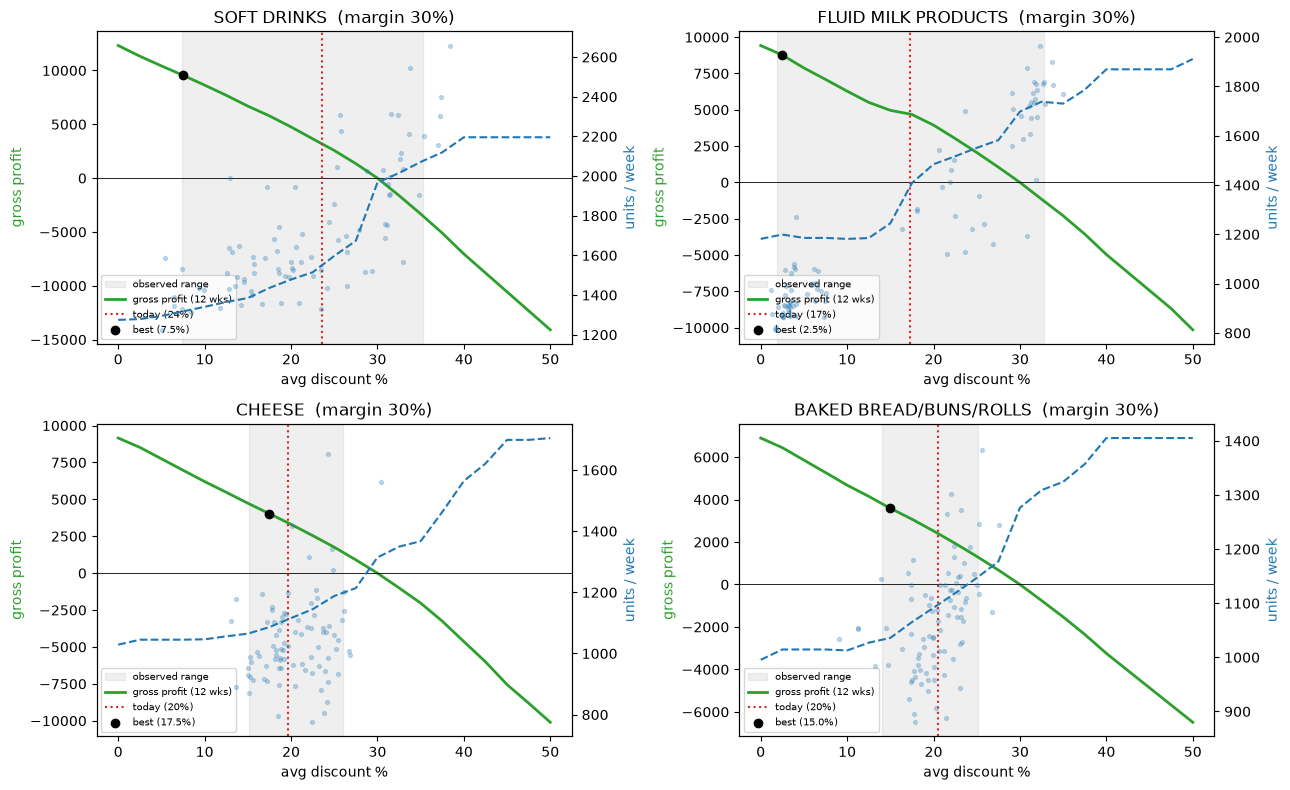

In [47]:
def plot_curve(ax, name):
    c = curves.loc[curves["item"] == name]
    cur = reco.loc[reco["item"] == name].iloc[0]
    hist = df.loc[df["item"] == name]
    n_weeks = len(SIM_WEEKS)

    ax.axvspan(c["disc_p05"].iloc[0], c["disc_p95"].iloc[0], color="grey", alpha=0.12, label="observed range")
    ax.plot(c["discount_pct"], c["gross_profit"], color="tab:green", lw=2, label="gross profit (12 wks)")
    ax.axhline(0, color="black", lw=0.6)
    ax.axvline(cur["current_discount"], color="tab:red", ls=":", label=f"today ({cur['current_discount']:.0f}%)")
    ax.scatter(cur["best_discount"], cur["best_profit"], color="black", zorder=5, label=f"best ({cur['best_discount']:.1f}%)")

    ax2 = ax.twinx()
    ax2.scatter(hist["avg_discount_pct"], hist["units"], s=8, color="tab:blue", alpha=0.25)
    ax2.plot(c["discount_pct"], c["units"] / n_weeks, color="tab:blue", ls="--", label="model units / week")
    ax2.set_ylabel("units / week", color="tab:blue")

    ax.set_title(f"{name}  (margin {cur['margin']:.0%})")
    ax.set_xlabel("avg discount %")
    ax.set_ylabel("gross profit", color="tab:green")
    ax.legend(loc="lower left", fontsize=7)

examples = [n for n in ["SOFT DRINKS", "FLUID MILK PRODUCTS", "CHEESE", "BAKED BREAD/BUNS/ROLLS"]
            if n in reco["item"].values]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, name in zip(axes.flat, examples):
    plot_curve(ax, name)
plt.tight_layout()
plt.savefig(FIGURES / "04_profit_curves.png", dpi=150)
plt.show()

## Best discount for every commodity

In [48]:
cols = ["item", "margin", "current_discount", "best_discount", "units_change_%",
        "current_profit", "best_profit", "profit_change", "recommendation"]

print("Biggest profit opportunities (normal-confidence commodities):")
display(usable.nlargest(15, "profit_change")[cols])

print("Losing money at today's discount (store pays full discount):")
display(usable.loc[usable["current_profit"] < 0, cols].sort_values("current_profit"))

Biggest profit opportunities (normal-confidence commodities):


,item,margin,current_discount,best_discount,units_change_%,current_profit,best_profit,profit_change,recommendation
119,SOFT DRINKS,0.30,23.59,7.50,-21.25,"2,613.86","9,552.34","6,938.48",discount less
80,FLUID MILK PRODUCTS,0.30,17.32,2.50,-13.05,"4,233.90","8,767.35","4,533.44",discount less
129,CHICKEN,0.25,34.94,25.00,-13.73,"-2,225.31",0.00,"2,225.31",discount less
131,PORK (MEAT),0.25,26.47,15.00,-20.32,-646.70,"1,241.17","1,887.88",discount less
128,BEEF,0.25,16.22,12.50,-6.70,"4,040.01","5,651.19","1,611.18",discount less
88,FRZN MEAT/MEAT DINNERS,0.30,20.56,15.00,-6.26,"2,710.19","4,139.90","1,429.71",discount less
95,ICE CREAM/MILK/SHERBTS,0.30,31.64,22.50,-9.38,-287.25,980.83,"1,268.08",discount less
47,BAKED BREAD/BUNS/ROLLS,0.30,20.49,15.00,-3.41,"2,359.78","3,589.73","1,229.94",discount less
140,LUNCHMEAT (MEAT-PCKGD),0.28,19.26,12.50,-9.24,"1,063.53","2,230.89","1,167.36",discount less
83,FROZEN PIZZA,0.30,17.50,12.50,-5.77,"3,176.33","4,255.12","1,078.79",discount less


Losing money at today's discount (store pays full discount):


,item,margin,current_discount,best_discount,units_change_%,current_profit,best_profit,profit_change,recommendation
129,CHICKEN,0.25,34.94,25.00,-13.73,"-2,225.31",0.00,"2,225.31",discount less
131,PORK (MEAT),0.25,26.47,15.00,-20.32,-646.70,"1,241.17","1,887.88",discount less
95,ICE CREAM/MILK/SHERBTS,0.30,31.64,22.50,-9.38,-287.25,980.83,"1,268.08",discount less
139,HOT DOGS,0.28,27.35,17.50,-11.88,-9.41,480.61,490.02,discount less


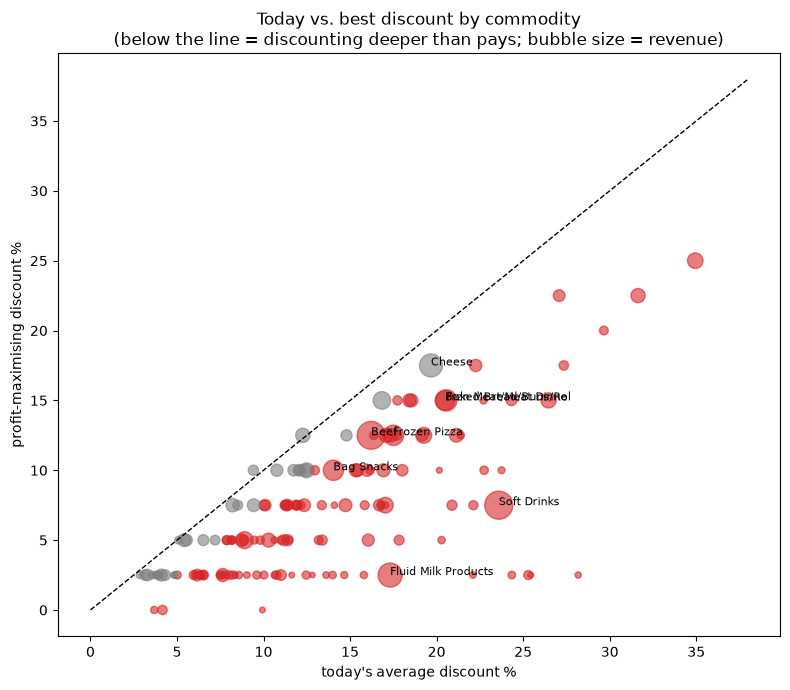

In [49]:
fig, ax = plt.subplots(figsize=(8, 7))
colors = usable["recommendation"].map({"discount less": "tab:red", "discount more": "tab:blue", "about right": "grey"})
size = usable["current_revenue"] / usable["current_revenue"].max() * 400 + 10
ax.scatter(usable["current_discount"], usable["best_discount"], c=colors, s=size, alpha=0.6)
lim = max(usable["current_discount"].max(), usable["best_discount"].max()) + 3
ax.plot([0, lim], [0, lim], color="black", lw=1, ls="--")
ax.set_xlabel("today's average discount %")
ax.set_ylabel("profit-maximising discount %")
ax.set_title("Today vs. best discount by commodity\n(below the line = discounting deeper than pays; bubble size = revenue)")
for _, r in usable.nlargest(8, "current_revenue").iterrows():
    ax.annotate(r["item"].title()[:20], (r["current_discount"], r["best_discount"]), fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "04_today_vs_best.png", dpi=150)
plt.show()

## Overall impact (base assumptions)

In [50]:
def impact_table(r):
    t = r[["current_units", "best_units", "current_revenue", "best_revenue", "current_profit", "best_profit"]].sum()
    out = pd.DataFrame({
        "today": [t["current_units"], t["current_revenue"], t["current_profit"]],
        "best discount": [t["best_units"], t["best_revenue"], t["best_profit"]],
    }, index=["units", "revenue", "gross profit"])
    out["change %"] = (out["best discount"] / out["today"] - 1) * 100
    return out

print(f"{len(usable)} commodities, weeks {min(SIM_WEEKS)}–{max(SIM_WEEKS)}, vendor-funded share {VENDOR_FUNDED_SHARE:.0%}")
impact_table(usable)

149 commodities, weeks 90–101, vendor-funded share 0%


,today,best discount,change %
units,"389,547.00","370,048.59",-5.01
revenue,"839,768.87","864,370.34",2.93
gross profit,"148,076.51","207,400.73",40.06


## Sensitivity: how much do the assumptions matter?

Re-run everything under different margins and different vendor-funded shares.
If the recommendations flip easily, I shouldn't present them with much confidence.

In [51]:
base_reco = usable.set_index("item")["recommendation"]
scenarios = []
for vendor_share in [0.0, 0.25, 0.5]:
    for shift in [-0.05, 0.0, 0.05]:
        _, r = evaluate(margin_shift=shift, vendor_share=vendor_share)
        r = r.loc[r["item"].isin(usable["item"])]
        imp = impact_table(r)
        same = (r.set_index("item")["recommendation"].reindex(base_reco.index) == base_reco).mean()
        counts = r["recommendation"].value_counts()
        scenarios.append({
            "vendor-funded share": f"{vendor_share:.0%}",
            "margin shift": f"{shift:+.0%}",
            "discount less": counts.get("discount less", 0),
            "about right": counts.get("about right", 0),
            "discount more": counts.get("discount more", 0),
            "same as base %": same * 100,
            "profit change %": imp.loc["gross profit", "change %"],
            "units change %": imp.loc["units", "change %"],
        })
sensitivity = pd.DataFrame(scenarios)
sensitivity

,vendor-funded share,margin shift,discount less,about right,discount more,same as base %,profit change %,units change %
0,0%,-5%,119,30,0,99.33,63.64,-5.18
1,0%,+0%,118,31,0,100.00,40.06,-5.01
2,0%,+5%,117,32,0,99.33,28.49,-4.95
3,25%,-5%,116,32,1,98.66,31.19,-4.90
4,25%,+0%,113,32,4,96.64,21.54,-4.25
5,25%,+5%,108,34,7,93.29,16.06,-3.58
6,50%,-5%,102,35,12,87.92,14.16,-2.87
7,50%,+0%,89,39,21,78.52,10.53,-0.57
8,50%,+5%,71,38,40,63.76,8.67,2.63


In [52]:
# best discount for the example commodities under each vendor-funded share
example_best = pd.DataFrame({
    f"vendor pays {v:.0%}": evaluate(vendor_share=v)[1].set_index("item")["best_discount"]
    for v in [0.0, 0.25, 0.5]
}).loc[examples]
example_best.insert(0, "today", reco.set_index("item").loc[examples, "current_discount"])
example_best

,today,vendor pays 0%,vendor pays 25%,vendor pays 50%
item,,,,
SOFT DRINKS,23.59,7.50,7.50,7.50
FLUID MILK PRODUCTS,17.32,2.50,2.50,2.50
CHEESE,19.67,17.50,17.50,17.50
BAKED BREAD/BUNS/ROLLS,20.49,15.00,15.00,15.00


## How much supplier funding would make today's discounts worth it?

For each commodity, find the smallest vendor-funded share at which today's discount level is (about) the
profit-maximising one. This turns the result into something a buyer can use when negotiating with suppliers.

In [53]:
shares = np.round(np.arange(0, 0.91, 0.1), 2)
best_by_share = pd.DataFrame({
    v: evaluate(vendor_share=v)[1].set_index("item")["best_discount"] for v in shares
})
today = reco.set_index("item")["current_discount"]

def needed_share(item):
    ok = best_by_share.loc[item] >= today[item] - 2.5
    return ok.idxmax() if ok.any() else np.nan

funding = usable[["item", "current_discount", "current_revenue"]].copy()
funding["vendor_share_needed"] = funding["item"].map(needed_share)
funding["label"] = funding["vendor_share_needed"].map(
    lambda v: "pays off without help" if v == 0 else ("not even at 90%" if pd.isna(v) else f"needs {v:.0%}+")
)
print(funding["label"].value_counts())
funding.nlargest(15, "current_revenue")

label
needs 70%+               35
pays off without help    31
needs 60%+               28
needs 80%+               17
needs 50%+               17
needs 90%+                7
needs 30%+                4
needs 40%+                4
needs 20%+                3
not even at 90%           2
needs 10%+                1
Name: count, dtype: int64


,item,current_discount,current_revenue,vendor_share_needed,label
119,SOFT DRINKS,23.59,"40,882.32",0.70,needs 70%+
128,BEEF,16.22,"40,208.68",0.70,needs 70%+
80,FLUID MILK PRODUCTS,17.32,"29,666.16",0.70,needs 70%+
60,CHEESE,19.67,"26,975.43",0.00,pays off without help
88,FRZN MEAT/MEAT DINNERS,20.56,"23,135.85",0.70,needs 70%+
83,FROZEN PIZZA,17.50,"21,048.61",0.80,needs 80%+
46,BAG SNACKS,14.04,"20,798.85",0.90,needs 90%+
47,BAKED BREAD/BUNS/ROLLS,20.49,"19,623.31",0.80,needs 80%+
63,COLD CEREAL,16.84,"15,490.37",0.00,pays off without help
4,DELI MEATS,8.91,"14,062.21",NaN,not even at 90%


## Save for the dashboard

In [54]:
curves.to_parquet(PROCESSED / "simulator_curves.parquet", index=False)
reco.to_parquet(PROCESSED / "discount_recommendations.parquet", index=False)
grid.to_parquet(PROCESSED / "simulator_grid.parquet", index=False)
sensitivity.to_parquet(PROCESSED / "simulator_sensitivity.parquet", index=False)
funding.to_parquet(PROCESSED / "vendor_funding_needed.parquet", index=False)
print("saved")

saved


## What I found

- **Break-even math:** at a 30% margin, a 15% discount needs 100% more units just to break even, and 20% off needs 200% more. The model's units curves follow the real weekly data closely (once display and mailer move with the discount the way they do in practice), and none of the big commodities come close to those uplifts.
- **If the store pays the whole discount:** about 80% of commodities are discounted deeper than pays off, and none would benefit from a deeper discount. Moving each one to its best level (staying inside the range the store has already tried) gives roughly 5% fewer units, 3% more revenue and about 40% more gross profit over 12 weeks.
- **Losing money today:** chicken, pork, ice cream and hot dogs make a loss at today's discount if the store funds it alone. These look like traffic builders (loss leaders) or are probably supplier-funded.
- **Supplier funding changes the answer, but not the direction:** with 50% vendor funding, most commodities are still discounted too deep, and the profit upside shrinks to about 11%. Margins ±5 points barely change the recommendations.
- **Supplier funding needed for today's discounts to pay off:** about 1 in 5 commodities pay off without help (e.g. cheese, cold cereal). About 2 in 5 need suppliers to cover 70% or more (soft drinks, beef, fluid milk). Bag snacks need around 90%, and deli meats don't pay off even at 90%.
- **So what:** the most useful output isn't "discount X%", it's a negotiation target: for each commodity, how much supplier funding the current promo depth requires.
- **Limitations:** margins and vendor funding are assumed; the best discount is only searched inside the range the store has tried; basket effects are ignored (customers who come in for a deal and buy other things); promo timing wasn't random, so any change should be tested on a few stores before rolling out.